# DamageNet-VGG16 — demo walkthrough
Transfer learning with VGG16 for road-damage patch classification on RDD2022 (SRM IST 21CSC406J case study).

This notebook only **loads saved results and figures** — run `python -m src.run_all` first.

In [1]:
import json, sys
from pathlib import Path
from IPython.display import Image, Markdown, display
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
R = ROOT / 'results'; F = ROOT / 'figures'

## 1. Results table

In [2]:
display(Markdown((R / 'summary.md').read_text()))

# DamageNet-VGG16 — results summary

Road-damage patch classification on RDD2022 (4 classes, class-balanced test set of 1200 patches).

## Main results

| Model | Test accuracy | Macro precision | Macro recall | Macro F1 | Val acc (best epoch) | Epochs run (best) |
|---|---|---|---|---|---|---|
| Baseline CNN (scratch, 64px) | 0.6892 | 0.6853 | 0.6892 | 0.6825 | 0.6713 | 30 (24) |
| VGG16 frozen (feature extraction, A4) | 0.7000 | 0.7050 | 0.7000 | 0.6992 | 0.7388 | 9 (4) |
| VGG16 fine-tuned (block 5) | 0.7167 | 0.7162 | 0.7167 | 0.7152 | 0.7462 | 4 (1) |

## Regularisation ablation (stage 1 head, cumulative)

| Run | Added | Test accuracy | Macro F1 | Final train acc | Final val acc |
|---|---|---|---|---|---|
| A0 | none | 0.6883 | 0.6890 | 1.000 | 0.690 |
| A1 | + dropout 0.5 | 0.6883 | 0.6889 | 0.996 | 0.695 |
| A2 | + L2 1e-3 | 0.6925 | 0.6930 | 0.996 | 0.703 |
| A3 | + horizontal-flip copies | 0.7083 | 0.7080 | 0.993 | 0.716 |
| A4 | + early stopping | 0.7000 | 0.6992 | 0.918 | 0.730 |

## Per-class F1

| Class | Baseline CNN (scratch, 64px) | VGG16 frozen (feature extraction, A4) | VGG16 fine-tuned (block 5) |
|---|---|---|---|
| D00 longitudinal crack | 0.680 | 0.664 | 0.677 |
| D10 transverse crack | 0.677 | 0.668 | 0.674 |
| D20 alligator crack | 0.560 | 0.649 | 0.668 |
| D40 pothole | 0.812 | 0.816 | 0.842 |

## Error analysis (VGG16 fine-tuned)

- Errors: 340 / 1200; **71.2% of errors are confusions between crack types** (D00/D10/D20).
- Top confusions: D10 → D00 (53), D10 → D20 (46), D20 → D00 (41), D00 → D20 (36), D20 → D10 (35), D00 → D10 (31)
- Accuracy by box size (thirds of max side, px): small 31–104: 0.780, medium 105–218: 0.651, large 219–2145: 0.719
- Accuracy by country: China_Drone 0.816 (n=49), China_MotorBike 0.698 (n=86), Czech 0.759 (n=29), India 0.774 (n=239), Japan 0.699 (n=422), Norway 0.686 (n=172), United_States 0.690 (n=203)

## Data

- Annotated images parsed: 35322; boxes kept: D00 26015, D10 11830, D20 10614, D40 6544
- Patches per class: train/val/test = 900/200/300

## Runtime

Pipeline steps (image downloads were already cached; a first run adds the rate-limited download time, ~45 min anonymous):

- 1. download + parse annotations: 0.1 min
- 2. build patch dataset: 0.6 min
- 3. baseline CNN: 1.9 min
- 4. VGG16 feature caching: 1.1 min
- 5. VGG16 stage 1 + ablation: 0.8 min
- 6. VGG16 stage 2 fine-tuning: 0.9 min
- 7. analysis: 0.0 min
- 8. figures: 0.0 min
- total: 5.4 min


## 2. Data: label distribution and sample patches

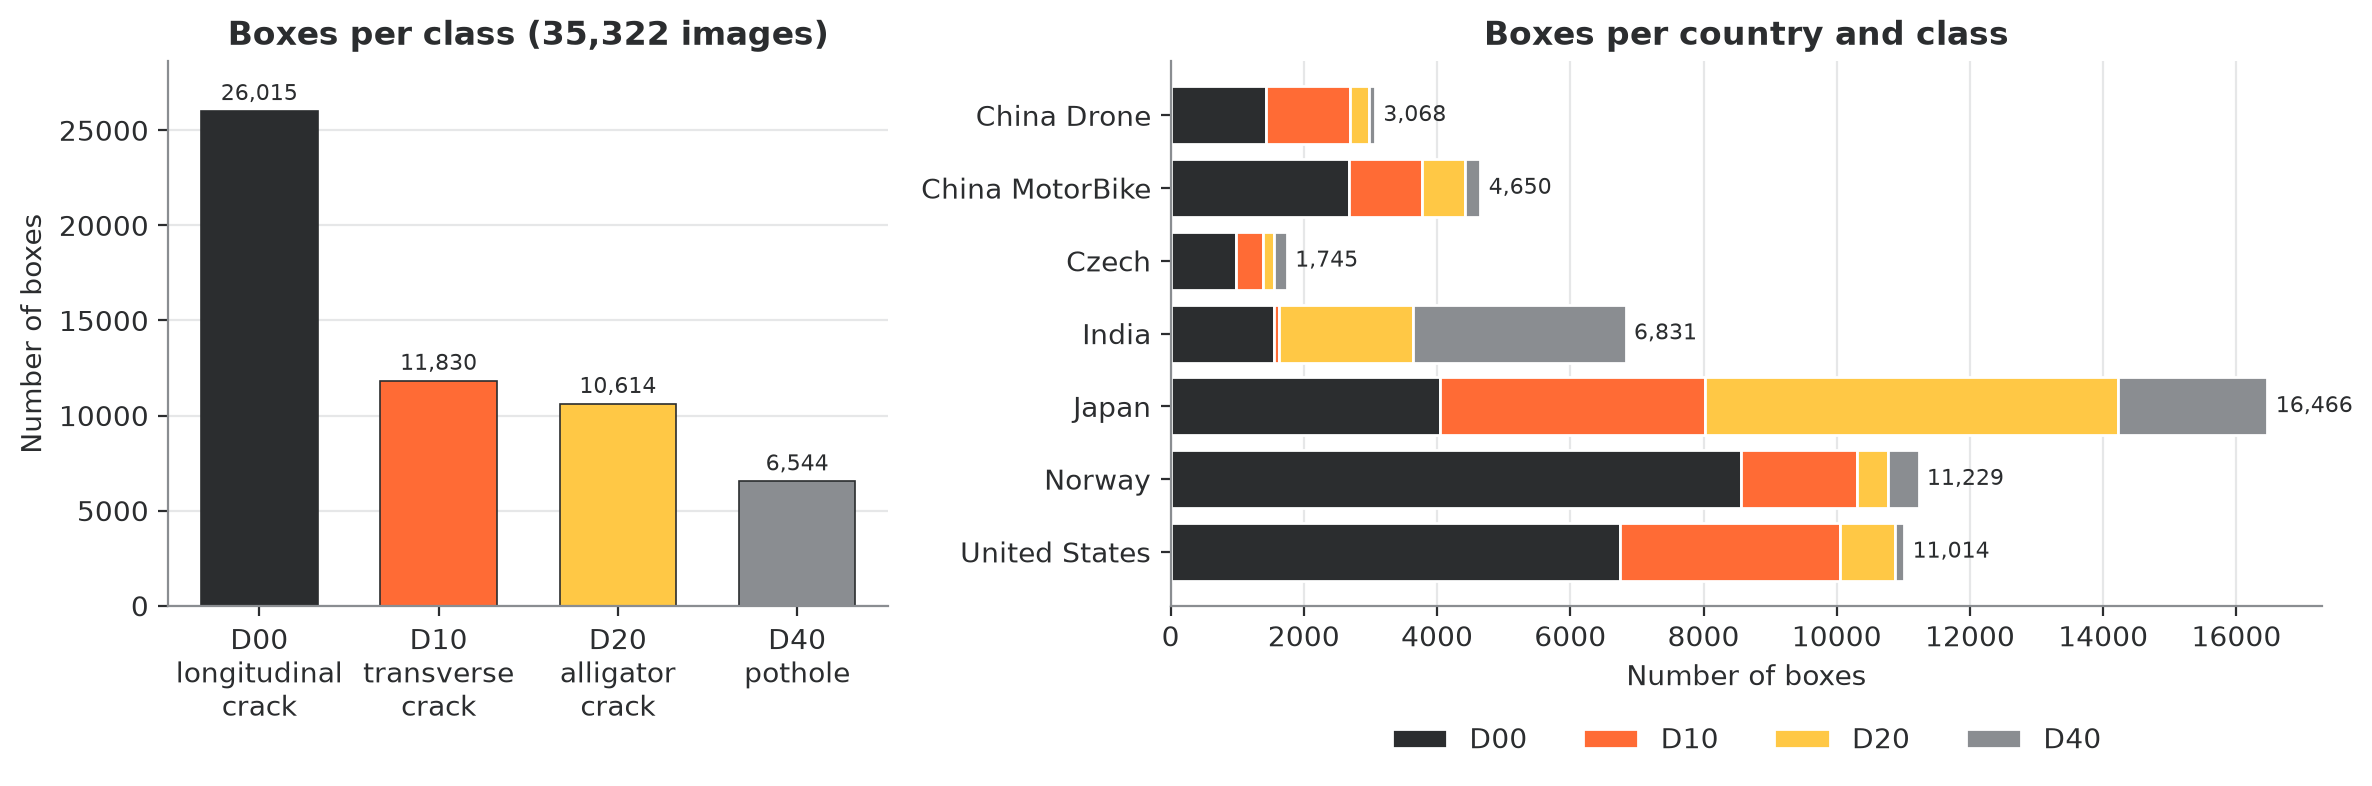

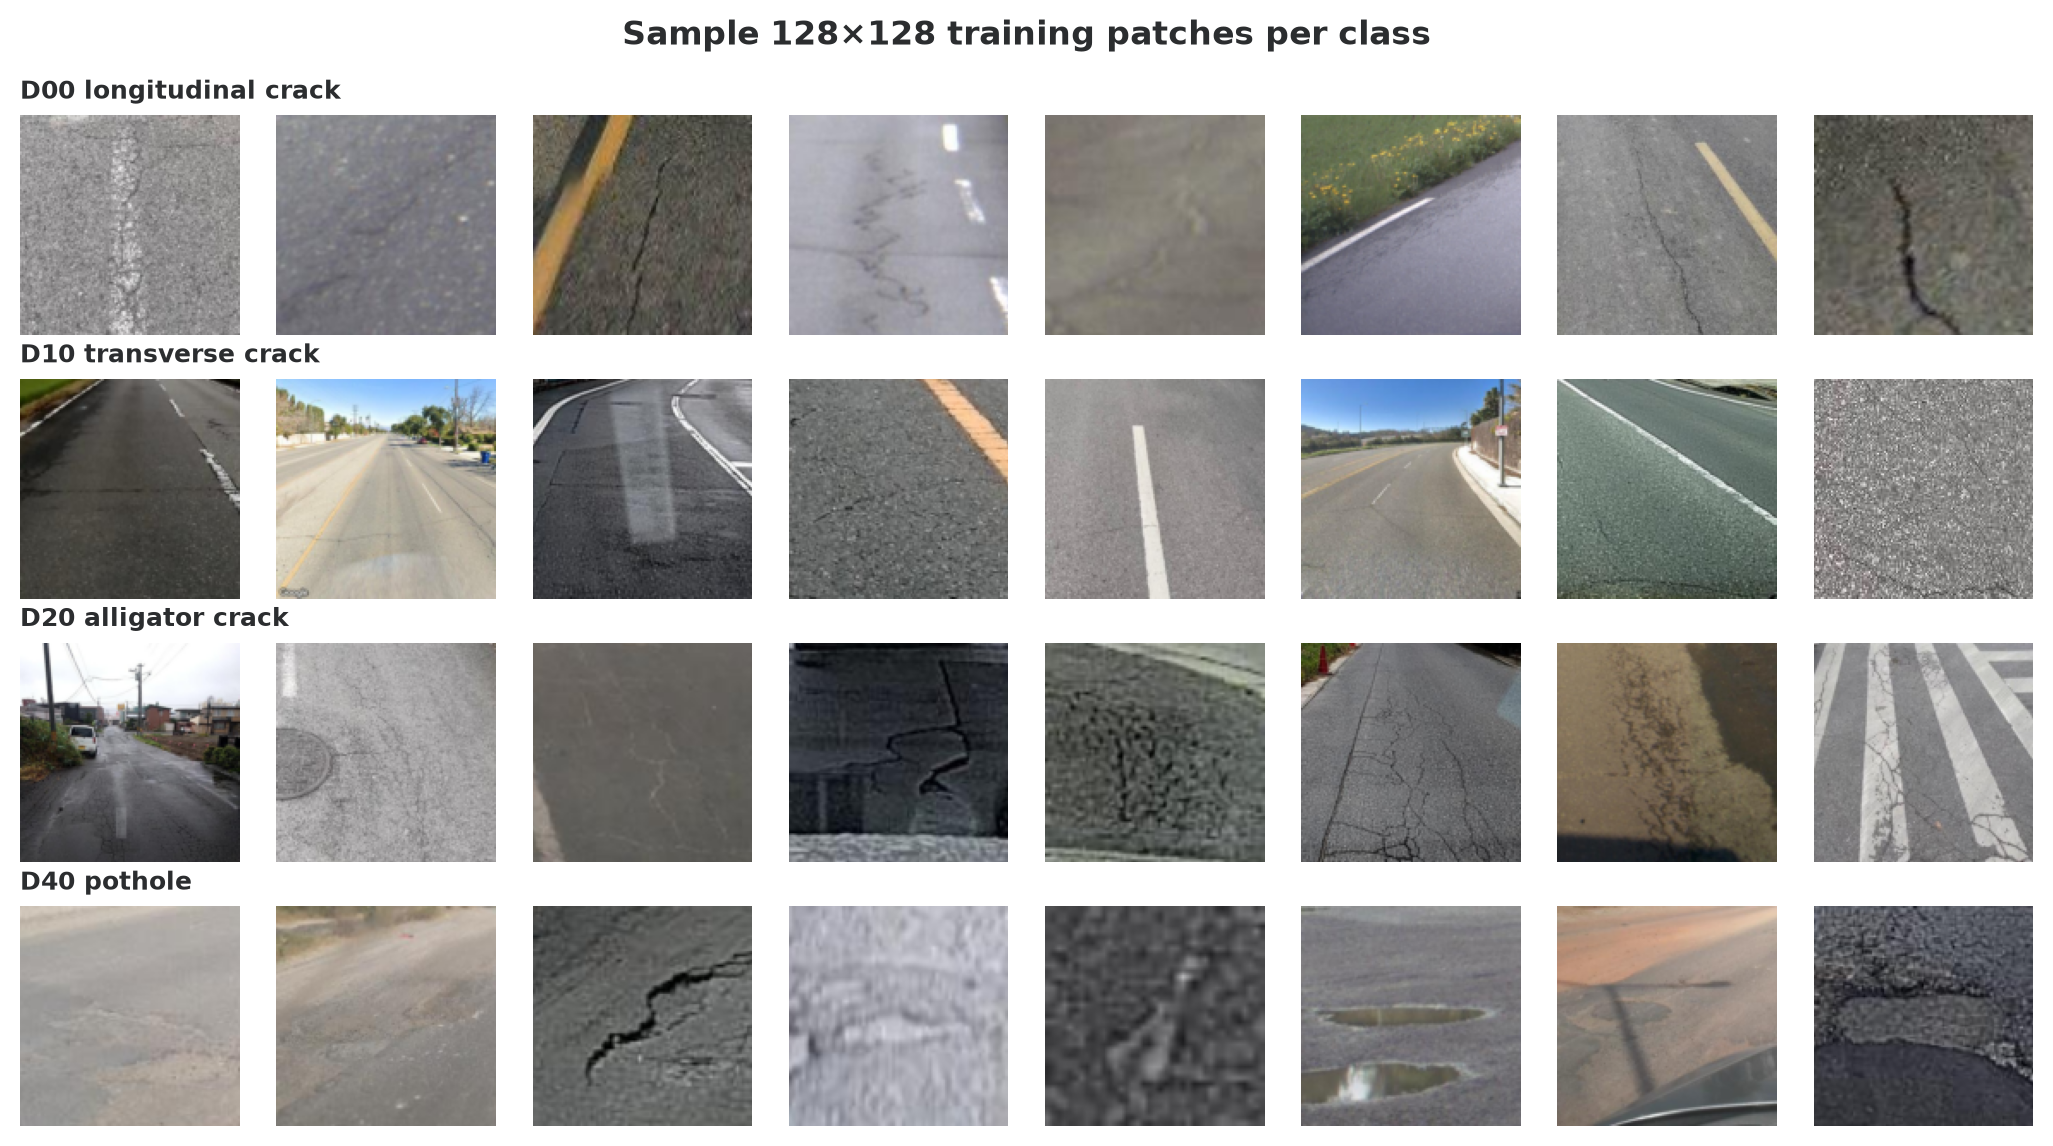

In [3]:
display(Image(F / 'label_distribution.png', width=900))
display(Image(F / 'sample_patches.png', width=700))

## 3. Model comparison and regularisation ablation

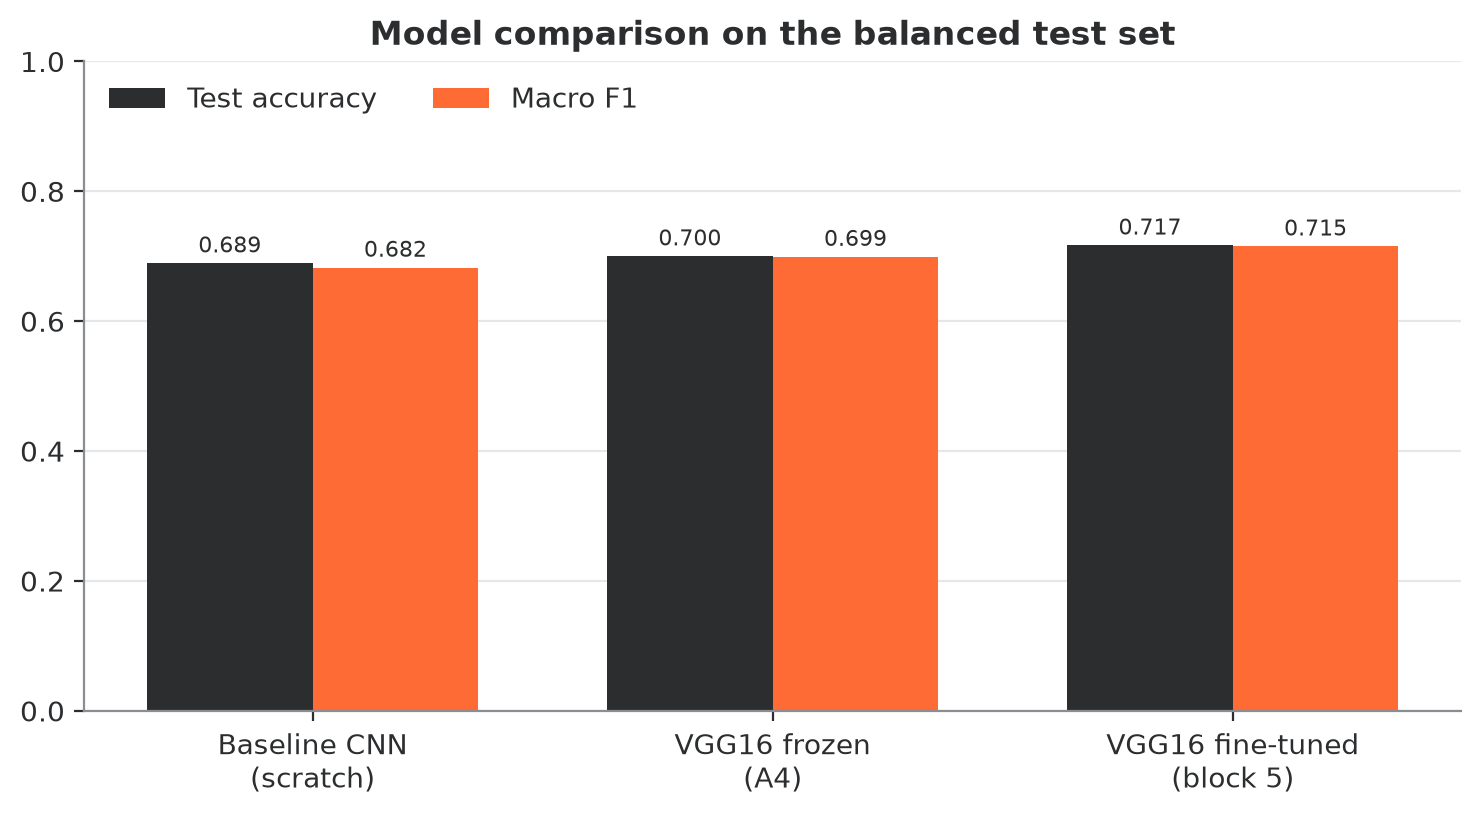

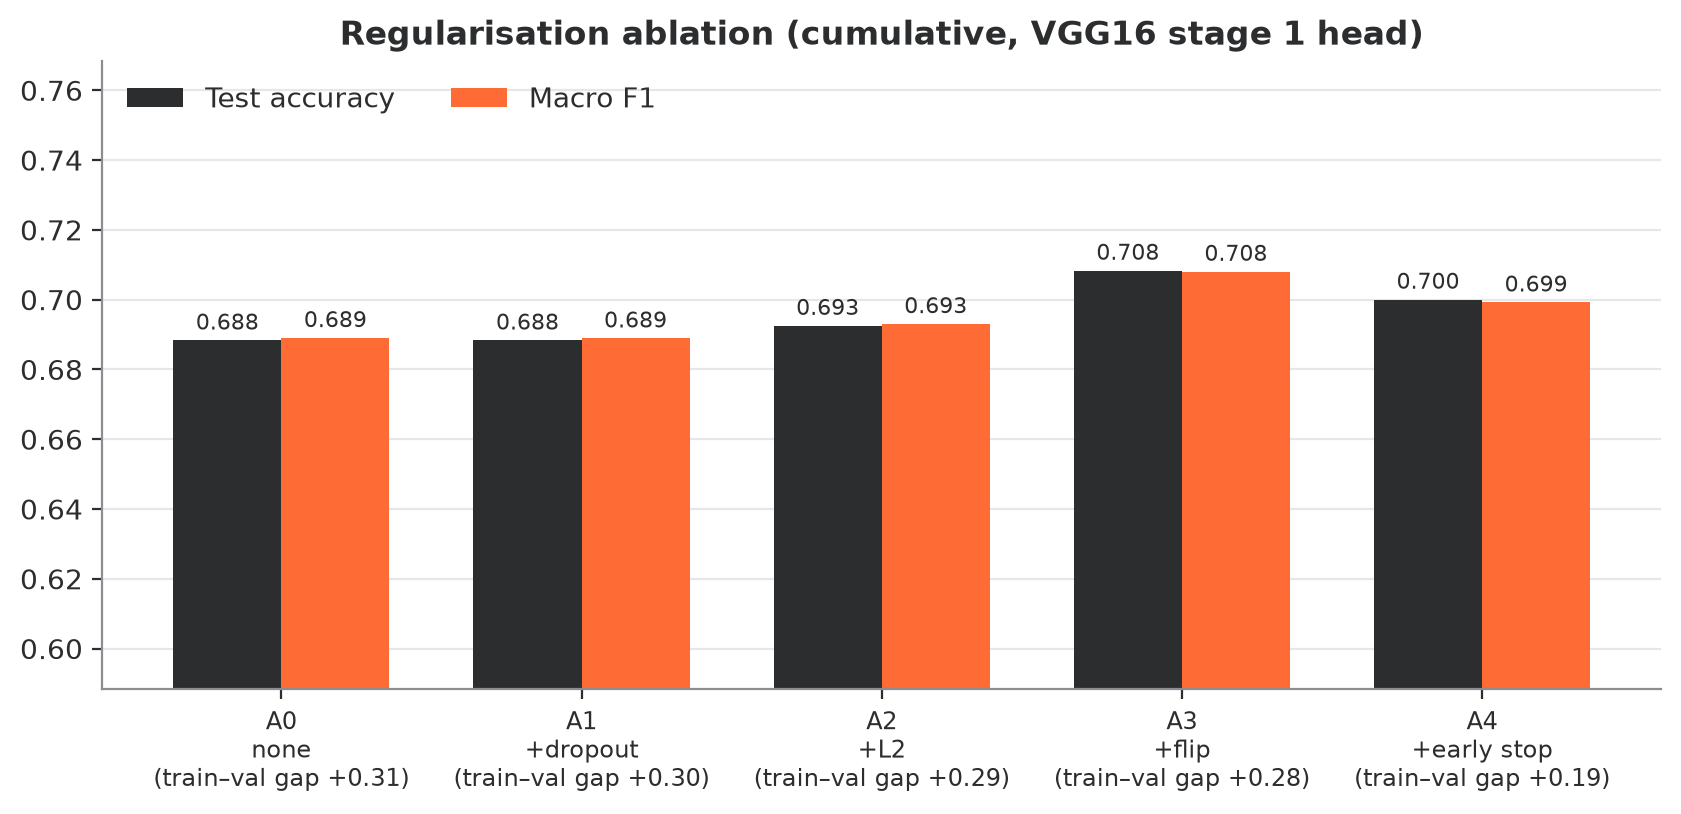

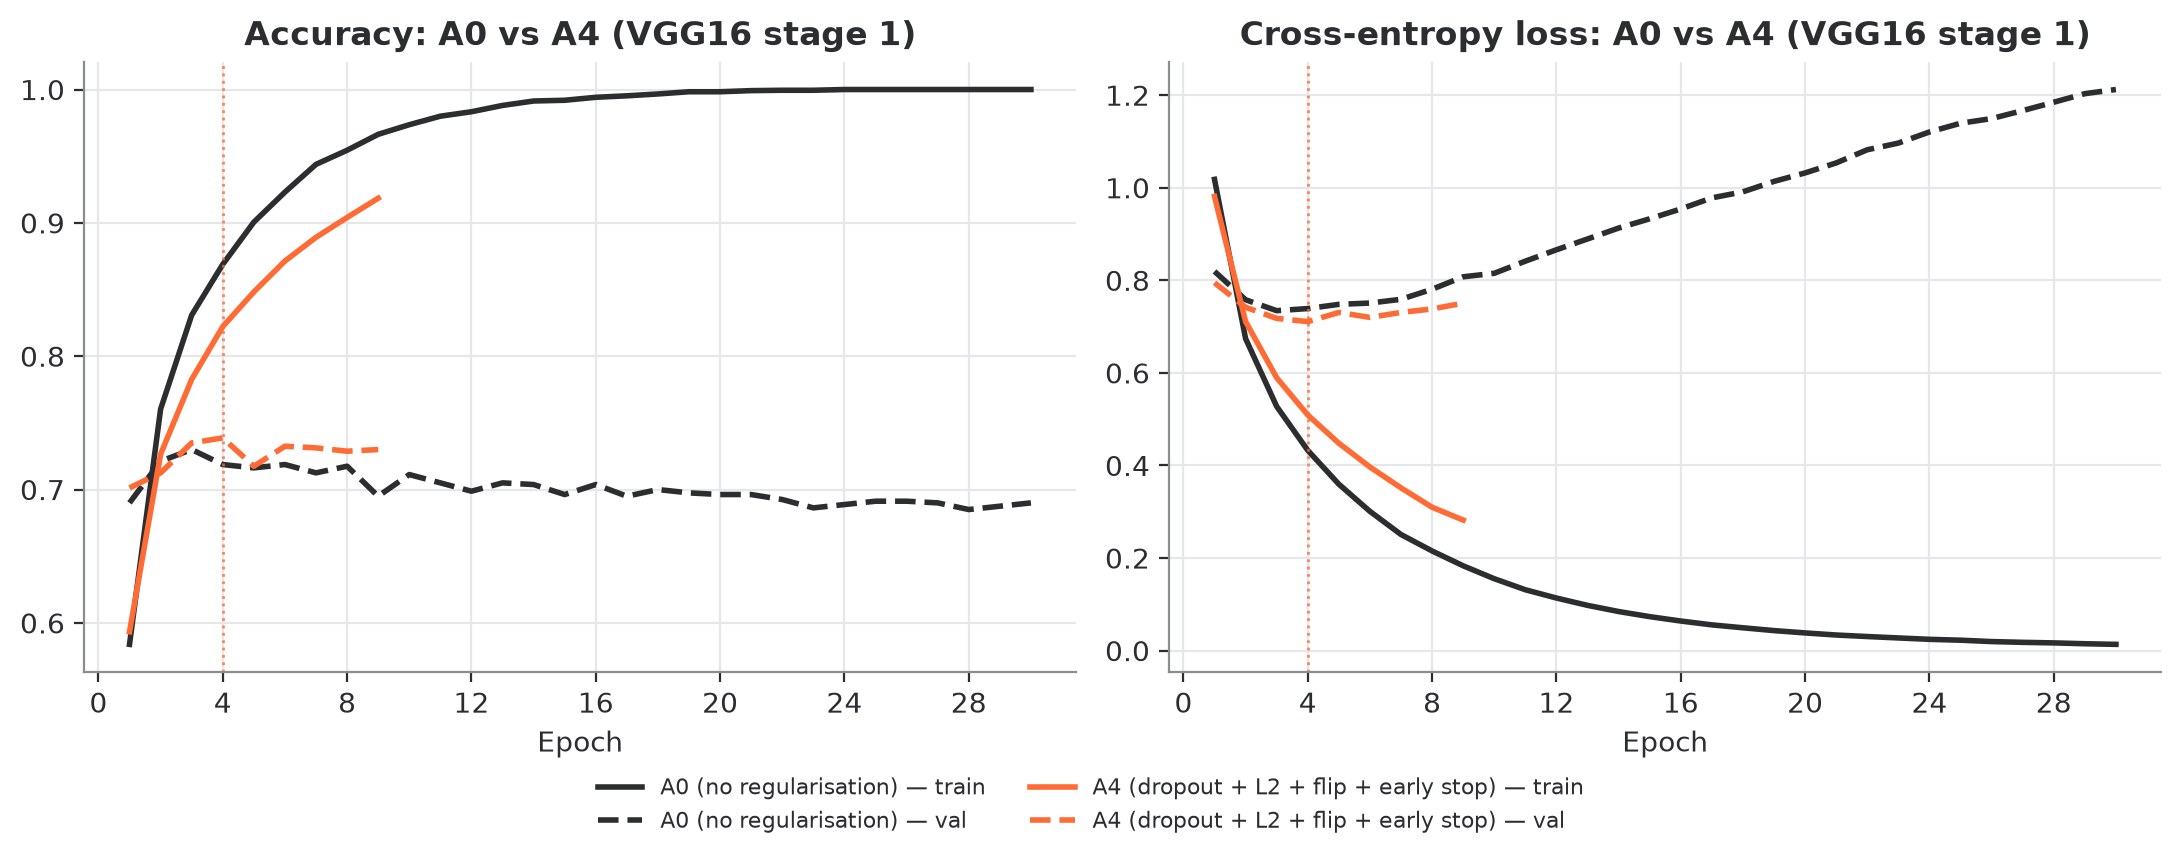

In [4]:
for n in ['model_comparison', 'ablation', 'learning_curves']:
    display(Image(F / f'{n}.png', width=800))

## 4. Fine-tuned VGG16: confusion matrix and per-class report

test accuracy 0.7167, macro F1 0.7152
         D00  P 0.656  R 0.700  F1 0.677
         D10  P 0.724  R 0.630  F1 0.674
         D20  P 0.669  R 0.667  F1 0.668
         D40  P 0.816  R 0.870  F1 0.842
   macro avg  P 0.716  R 0.717  F1 0.715
weighted avg  P 0.716  R 0.717  F1 0.715


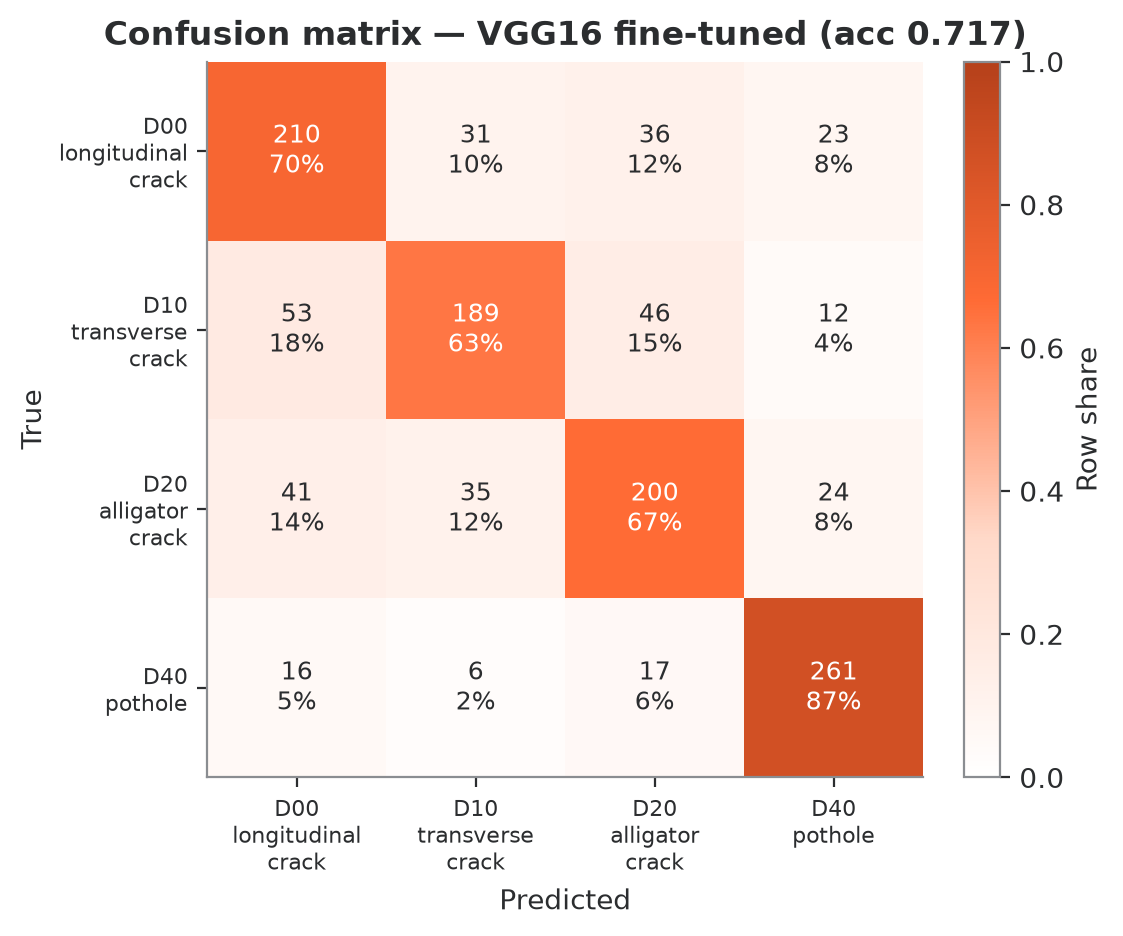

In [5]:
ft = json.loads((R / 'vgg16_ft.json').read_text())
print(f"test accuracy {ft['test_accuracy']:.4f}, macro F1 {ft['macro_f1']:.4f}")
for c, v in ft['classification_report'].items():
    if isinstance(v, dict):
        print(f"{c:>12}  P {v['precision']:.3f}  R {v['recall']:.3f}  F1 {v['f1-score']:.3f}")
display(Image(F / 'confusion_matrix.png', width=520))

## 5. Error analysis

crack-type share of errors: 0.7118
top confusions: [('D10', 'D00', 53), ('D10', 'D20', 46), ('D20', 'D00', 41), ('D00', 'D20', 36), ('D20', 'D10', 35), ('D00', 'D10', 31)]
by country: {'China_Drone': 0.8163, 'China_MotorBike': 0.6977, 'Czech': 0.7586, 'India': 0.7741, 'Japan': 0.6991, 'Norway': 0.686, 'United_States': 0.6897}
by box size: {'small': 0.78, 'medium': 0.6509, 'large': 0.7193}


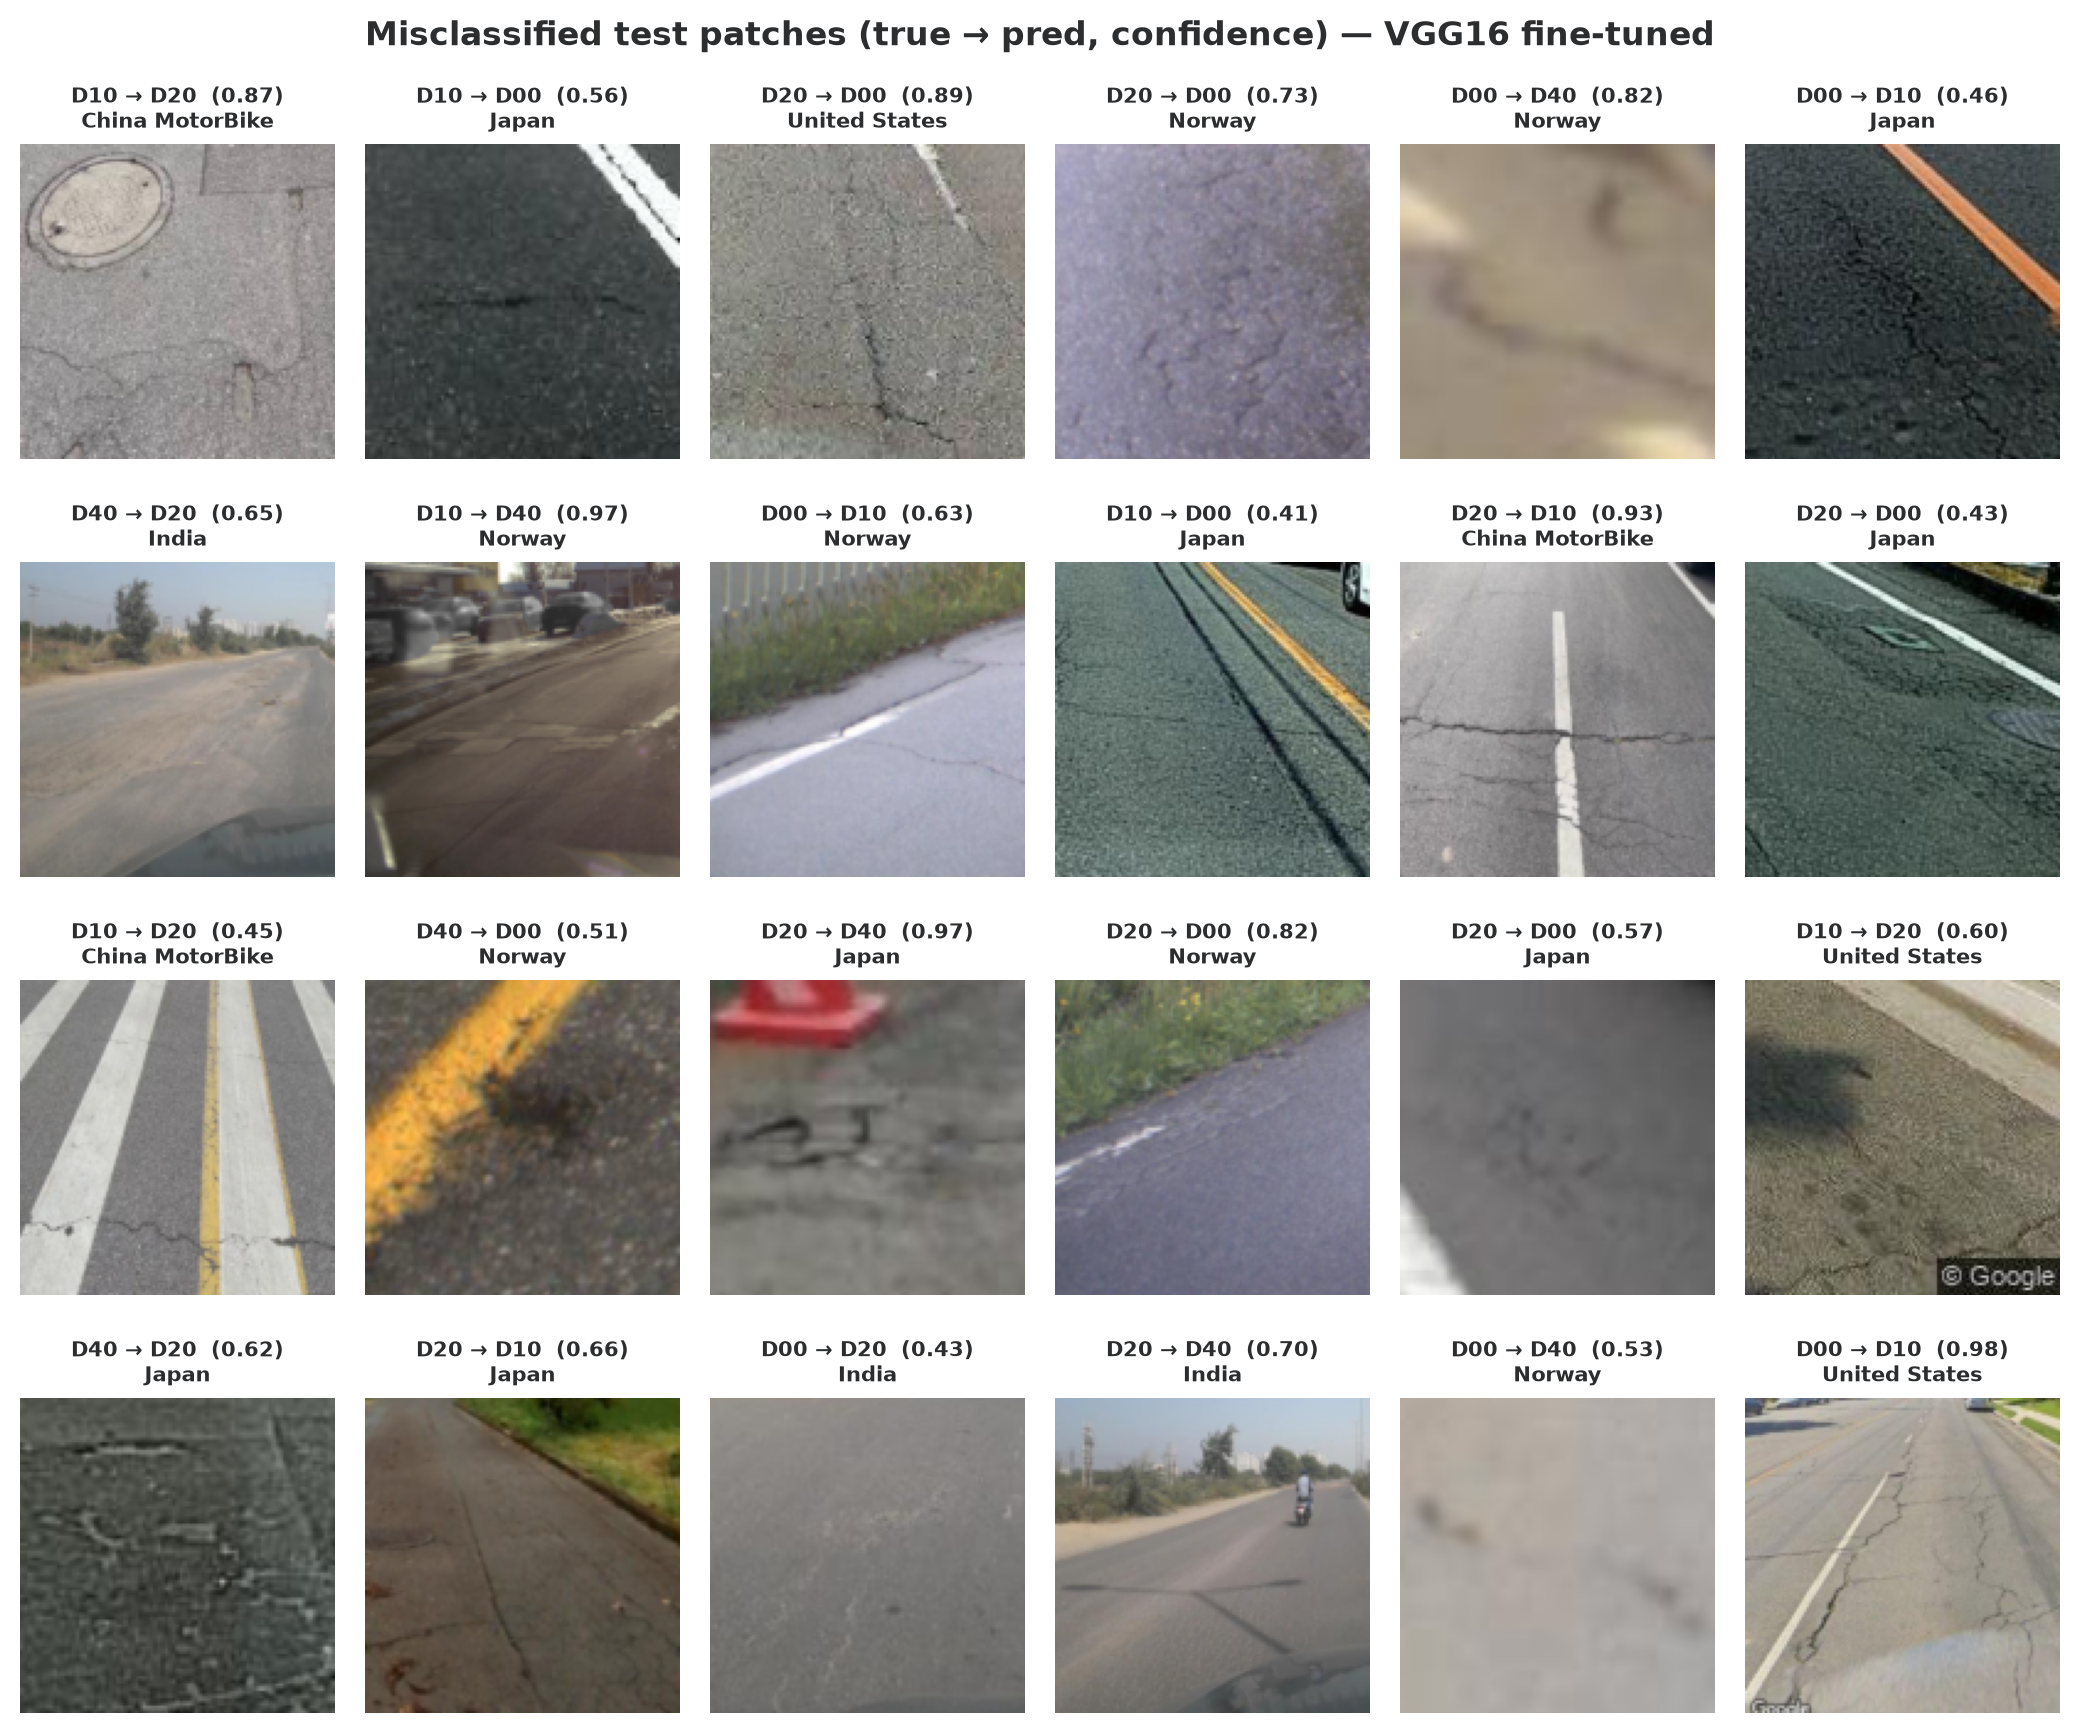

In [6]:
an = json.loads((R / 'analysis.json').read_text())
print('crack-type share of errors:', an['crack_confusion_share'])
print('top confusions:', [(t['true'], t['pred'], t['count']) for t in an['top_confusions']])
print('by country:', {k: v['accuracy'] for k, v in an['accuracy_by_country'].items()})
print('by box size:', {k: v['accuracy'] for k, v in an['accuracy_by_box_size'].items()})
display(Image(F / 'misclassified.png', width=850))

## 6. Predict one test patch with the saved checkpoint (optional)
Needs `checkpoints/vgg16_ft.pt` and the patch dataset.

In [7]:
import numpy as np, torch
from src.models import VGG16Classifier
ck = ROOT / 'checkpoints' / 'vgg16_ft.pt'
npz = ROOT / 'data' / 'patches' / 'test.npz'
if ck.exists() and npz.exists():
    c = torch.load(ck, map_location='cpu')
    m = VGG16Classifier(c['hidden'], c['dropout'], 4, pretrained=False); m.load_state_dict(c['state_dict']); m.eval()
    d = np.load(npz); i = 7
    x = torch.from_numpy(d['x'][i]).permute(2, 0, 1).float().div(255)[None]
    p = torch.softmax(m(x), 1)[0].detach().numpy()
    print('true', c['classes'][d['y'][i]], '| pred', c['classes'][p.argmax()], np.round(p, 3))
else:
    print('checkpoint or patches not available — skipped')

true D00 | pred D00 [0.787 0.001 0.016 0.196]
